# Quasiharmonic Approximations (QHA) for $\ce{Si}$ with [MatterSim](https://github.com/microsoft/mattersim)

## Import Necessary Packages

In [1]:
import numpy as np
from pylab import *

## Custom Define Functions

In [2]:
def set_fig_properties(ax_list, panel_color_str='black', line_width=2):
    tl = 4
    tw = 2
    tlm = 2

    for ax in ax_list:
        ax.tick_params(which='major', length=tl, width=tw)
        ax.tick_params(which='minor', length=tlm, width=tw)
        ax.tick_params(which='both', axis='both', direction='in',
                       right=True, top=True)
        ax.spines['bottom'].set_color(panel_color_str)
        ax.spines['top'].set_color(panel_color_str)
        ax.spines['left'].set_color(panel_color_str)
        ax.spines['right'].set_color(panel_color_str)

        ax.spines['bottom'].set_linewidth(line_width)
        ax.spines['top'].set_linewidth(line_width)
        ax.spines['left'].set_linewidth(line_width)
        ax.spines['right'].set_linewidth(line_width)

        for t in ax.xaxis.get_ticklines(): t.set_color(panel_color_str)
        for t in ax.yaxis.get_ticklines(): t.set_color(panel_color_str)
        for t in ax.xaxis.get_ticklines(): t.set_linewidth(line_width)
        for t in ax.yaxis.get_ticklines(): t.set_linewidth(line_width)

## Denote Latex Font for Plots

In [3]:
# Denote plot default format
aw = 2
fs = 12
font = {'size': fs}
matplotlib.rc('font', **font)
matplotlib.rc('axes', linewidth=aw)

# Configure Matplotlib to use a LaTeX-like style without LaTeX
plt.rcParams['text.usetex'] = False
plt.rcParams['font.family'] = 'serif'
plt.rcParams['mathtext.fontset'] = 'cm'

## Illustrate $\alpha$ vs. T up till Room temperature
- Experimental $\alpha$ from 7 to 293 K are adopted from:  https://link.aps.org/doi/10.1103/PhysRevB.92.174113

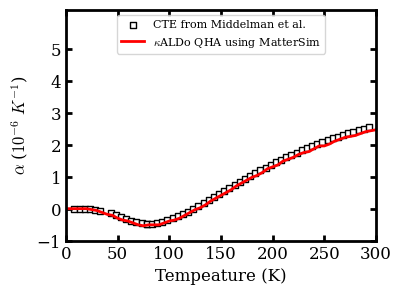

In [4]:
# Initalize temperature array and low in thermal expansion coefficients
temperature = np.linspace(0, 1800, 361)
coefficients_of_thermal_expansions = np.load('kaldo_runs/alpha_T.npy', allow_pickle=True)
lattice = np.load('kaldo_runs/L_T.npy', allow_pickle=True)
free_energies = np.load('kaldo_runs/F_T.npy', allow_pickle=True)

# Load in low temperature alpha data
data_Middelmann = np.loadtxt('Si_thermal_expansion_7-293K.dat')
temperature_exp_Middelmann = data_Middelmann [:,0]
alpha_exp_Middelmann = data_Middelmann [:,1]

fig = figure(figsize=(4,3))
set_fig_properties([gca()])
scatter(temperature_exp_Middelmann, alpha_exp_Middelmann, edgecolor='k', facecolor='w', marker='s', s=20, zorder=1, label='CTE from Middelman et al.')
#scatter(temperature_exp_Okada, alpha_exp_Okada, edgecolor='k', facecolor='w', marker='o', s=20, zorder=1, label='CTE from Okada et al.')
plot(temperature, 1e6 * coefficients_of_thermal_expansions, 'r-', lw=2, label=r'$\kappa$ALDo QHA using MatterSim')
legend(loc='upper center', fontsize=8)
gca().set_xticks(np.arange(0, 2100, 50))
gca().set_yticks(np.arange(-1, 6, 1))
xlabel('Tempeature (K)')
ylabel(r'$\alpha$ ($10^{-6} \ K^{-1}$)')
xlim([0, 300])
show()

## Plot thermal expansion ($\alpha$), lattice constants $\&$ free energies
- Experimental $\alpha$ from 300 to 1500 K are adopted from:  https://pubs.aip.org/jap/article/56/2/314/170925/Precise-determination-of-lattice-parameter-and

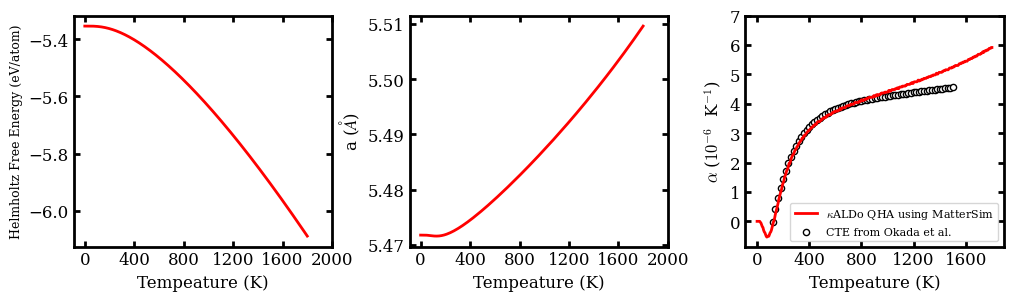

In [5]:
# Load in high temperature alpha data
data_Okada = np.loadtxt('Si_thermal_expansion_OkadaTokumaru1984.dat')
temperature_exp_Okada = data_Okada[:,0]
alpha_exp_Okada = data_Okada[:,1]

fig = figure(figsize=(12,3))

subplot(1,3,1)
set_fig_properties([gca()])
plot(temperature, free_energies/1000, 'r-', lw=2)
gca().set_xticks(np.arange(0, 2400, 400))
xlabel('Tempeature (K)')
ylabel(r"Helmholtz Free Energy (eV/atom)", fontsize=9)


subplot(1,3,2)
set_fig_properties([gca()])
plot(temperature, lattice, 'r-', lw=2)
gca().set_xticks(np.arange(0, 2400, 400))
xlabel('Tempeature (K)')
ylabel(r'a ($\AA$)')

subplot(1,3,3)
set_fig_properties([gca()])
plot(temperature, 1e6 * coefficients_of_thermal_expansions, 'r-', lw=2, label=r'$\kappa$ALDo QHA using MatterSim')
scatter(temperature_exp_Okada, alpha_exp_Okada, edgecolor='k', facecolor='w', marker='o', s=20, zorder=1, label='CTE from Okada et al.')
gca().set_yticks(np.arange(0, 8, 1))
gca().set_xticks(np.arange(0, 2000, 400))
xlabel('Tempeature (K)')
ylabel(r'$\alpha$ ($10^{-6}$  K$^{-1}$)')
legend(loc='lower right', fontsize=8)
subplots_adjust(hspace=0, wspace=0.3)
show()